# Evidencia temporal: ¿válido cuándo y conocido cuándo?

## Resumen
En 56 consultas por política, última versión produce 48 citas incorrectas y filtro sólo por validez 40; ambos usan conocimiento futuro en 24 casos. Dos relojes devuelve 32 citas correctas, 16 not_found y ocho ambiguous. No se cuenta la ausencia como respuesta factual acertada. Son fixtures sintéticas, sin normas reales ni LLM.

## Contexto y método

Una fila es elegible si
$$v_{inicio}\leq t_v<v_{fin}\quad\land\quad k_{inicio}\leq t_k<k_{fin}.$$
Fin nulo representa abierto. El gate devuelve una única versión o no cita cuando no hay candidato o existe conflicto. No selecciona el último registro para ocultar un solapamiento.

### Supuestos
Los intervalos y el tiempo registrado son confiables; granularidad diaria. known_on significa lo registrado localmente, no lo que todos los actores sabían. No inferencia de jerarquía legal. Snodgrass explica ambos tiempos; SQL Server system time no equivale automáticamente a business valid time. Referencias en referencias.bib.

## Datos y configuración
Ocho variantes × siete casos: antes del primer registro, conocimiento antiguo, corrección retroactiva, validez nueva/conocimiento antiguo, ambos nuevos, expiración y conflicto. Cada caso tiene verdad esperada manual, independiente de los filtros. Todo texto indica SYNTHETIC ONLY.

In [1]:
import json
from pathlib import Path
from IPython.display import display, SVG
r=json.loads(Path("results/summary.json").read_text())
r["config"]

Out[1]: 
{'seeds': [0, 1, 2, 3, 4, 5, 6, 7],
 'intervals': '[start,end), date-granularity, None=end-unbounded',
 'hypothesis': 'bitemporal gate zero wrong definite citations and zero future leaks; latest and valid_only have >0 future leaks; conflict returns no citation',
 'data': 'synthetic version rectangles with retroactive correction, expiry and conflicting overlap; no legal/regulatory statements',
 'selection': [{'idea': 'bitemporal evidence gate',
   'decision': 'selected',
   'reason': 'new pilar06 S1 gap, prevents knowledge-time leakage before RAG retrieval'},
  {'idea': 'retrieval LRU cache',
   'decision': 'deferred',
   'reason': 'routing/cache project already implemented'},
  {'idea': 'memory TTL',
   'decision': 'deferred',
   'reason': 'near outbox prior cycle'}]}


## Consulta mínima viva
Una corrección registrada en marzo cambia una regla de enero. Si la pregunta usa el estado conocido en febrero, no debe recibir la corrección futura.

In [2]:
from src.fixtures import fixture
from src.temporal import select, integrity_ok
versions,_=fixture(0)
for mode in ("latest","valid_only","bitemporal"):
    result=select(versions,"synthetic-rule-0","2026-01-15","2026-02-15",mode)
    print(mode,result.status,[(c.version.version_id,c.version.known_from,integrity_ok(c)) for c in result.citations])
for row in r["summary"]:
    print(row)

latest ok [('s0-v2b', '2026-03-01', True)]
valid_only ok [('s0-v2a', '2026-03-01', True)]
bitemporal ok [('s0-v1', '2026-01-01', True)]
{'mode': 'latest', 'queries': 56, 'answers': 56, 'wrong_definite': 48, 'contract_matches': 8, 'future_leaks': 24, 'knowledge_violations': 24, 'validity_violations': 32, 'not_found': 0, 'ambiguous': 0, 'mean_seconds': 0.0003254045892820808, 'max_python_peak_bytes': 1916}
{'mode': 'valid_only', 'queries': 56, 'answers': 56, 'wrong_definite': 40, 'contract_matches': 16, 'future_leaks': 24, 'knowledge_violations': 32, 'validity_violations': 0, 'not_found': 0, 'ambiguous': 0, 'mean_seconds': 0.0003582459464236568, 'max_python_peak_bytes': 1836}
{'mode': 'bitemporal', 'queries': 56, 'answers': 32, 'wrong_definite': 0, 'contract_matches': 56, 'future_leaks': 0, 'knowledge_violations': 0, 'validity_violations': 0, 'not_found': 16, 'ambiguous': 8, 'mean_seconds': 0.0003813603928587587, 'max_python_peak_bytes': 1828}


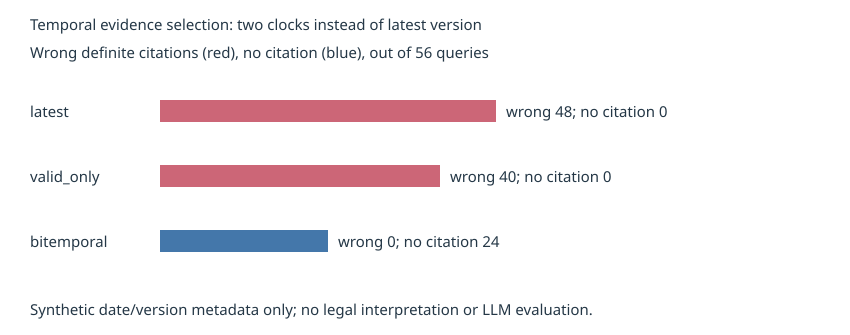

In [3]:
display(SVG(filename="results/temporal.svg"))

### Lectura
Azul significa ninguna cita, con razón explícita: falta de evidencia o conflicto. No implica recuperación correcta de todos los documentos pertinentes. Validar sólo la fecha de aplicabilidad evita algunas versiones fuera de vigencia, pero sigue admitiendo conocimiento futuro o registros ya reemplazados.

In [4]:
rows={x["mode"]:x for x in r["summary"]}
assert rows["bitemporal"]["wrong_definite"]==0
assert rows["bitemporal"]["future_leaks"]==0
assert rows["bitemporal"]["answers"]==32
assert rows["bitemporal"]["ambiguous"]==8
assert rows["latest"]["future_leaks"]>0
assert rows["valid_only"]["future_leaks"]>0
print("Hipótesis de metadata temporal satisfecha en estas fixtures, no validación legal/RAG general.")
r["environment"]

Hipótesis de metadata temporal satisfecha en estas fixtures, no validación legal/RAG general.
Out[1]: 
{'python': '3.12.14',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39',
 'processor': 'x86_64',
 'cpu_count': 9}


## Conclusiones y siguiente prueba
Hay dos preguntas temporales diferentes y deben persistirse ambos ejes. Un hash versiona la evidencia seleccionada, pero no prueba su verdad. Próximo paso: ingestion append-only con fechas de fuente y registro separadas, seguida de retrieval real y evaluación independiente. Notebook ejecutado con IPython in-process, no kernel aislado.